# Setup


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('labeled_data.csv')
data.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


# Exploration & Preprocessing

Question: drop "count" or no? Minimum number of count required is always 3, so there is no data that will be missing due to a lesser count. However, perhaps the model can be more confident in its prediction if more people have labelled the data and confirmed the nature of the tweet?

Dropping unwanted columns. Additionally, plotting the classes to check for imbalance.

class labels are as follows: 
- 0 - hate speech 
- 1 - offensive language 
- 2 - neither


In [3]:
#dropping unwanted columns. 
data =data.drop(columns= ['Unnamed: 0', 'hate_speech', 'offensive_language', 'neither'])
data.head()


,count,class,tweet
0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,3,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,3,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,6,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


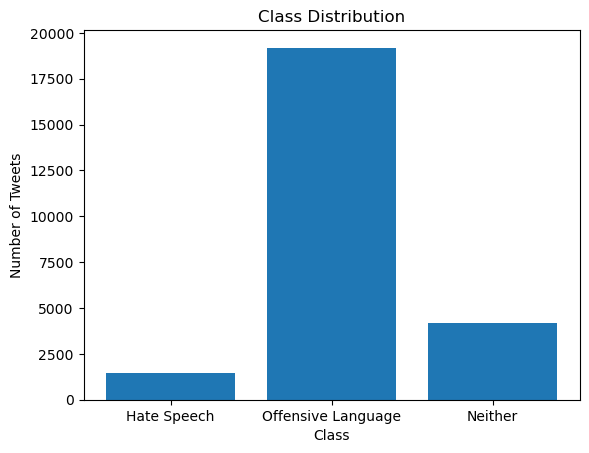

In [4]:
plt.bar(data['class'].value_counts().index, data['class'].value_counts().values)

plt.xlabel('Class')
plt.ylabel('Number of Tweets')
plt.title('Class Distribution')
plt.xticks([0, 1, 2], ['Hate Speech', 'Offensive Language', 'Neither'])

plt.show()


Dataset is highly imbalanced, with most tweets being labelled offensive. We will need to balance the data.

In [5]:
#Checking null values
data.isna().sum()

count    0
class    0
tweet    0
dtype: int64

Checking data contents

In [6]:
data.tweet.iloc[10]

'" Keeks is a bitch she curves everyone " lol I walked into a conversation like this. Smh'

In [7]:
data.tweet.iloc[100]

'"@ClicquotSuave: LMAOOOOOOOOOOO this nigga @Krillz_Nuh_Care http://t.co/AAnpSUjmYI" &lt;bitch want likes for some depressing shit..foh'

Tweets contain links, mentions, and retweets. We can remove the links by removing anything after "http" up until the next space; remove mentions by removing anything followed directly by an '@', till the next space; and remove the term 'RT' indicating retweets. 

Additionally, the tweets show that there are are special characters that need to be cleaned, along with HTML characters.
Punctuation and numbers can be important when analyzing text in NLP, for our usecase these could be used to circumvent flagging by using numbers and punctuation to spell out slurs or other offensicve terms. Hence, we keep them.

Lastly, we remove any long spaces.

In [8]:
import re
import html

def clean_tweet(tweet):
    tweet = html.unescape(str(tweet))
    tweet = re.sub(r'http\S*', '', tweet) #removing one or more characters that come after 'http' provided they are not spaces
    tweet = re.sub(r'@\S*', '', tweet) #removing usernames
    tweet = re.sub(r'\bRT\b', '', tweet) #removing 'RT'
    tweet = tweet.replace("#", '') # keeping hashtag words, removing only the # symbol
    tweet = re.sub(r"^!+", '', tweet) #removing the random exclamation marks at the start


    return tweet

data['cleaned_tweet'] = data['tweet'].apply(clean_tweet)
data.cleaned_tweet.iloc[100]

'" LMAOOOOOOOOOOO this nigga   <bitch want likes for some depressing shit..foh'

In [9]:
data = data.drop(columns= 'tweet')
data.head()

,count,class,cleaned_tweet
0,3,2,As a woman you shouldn't complain about cle...
1,3,1,boy dats cold...tyga dwn bad for cuffin dat...
2,3,1,Dawg!!!! You ever fuck a bitch and she st...
3,3,1,she look like a tranny
4,6,1,The shit you hear about me might be true or...


In [18]:
#Randomly selecting tweets to check for any further cleaning required
data.cleaned_tweet.iloc[2]

'dawg!!!!   you ever fuck a bitch and she start to cry? you be confused as shit'

In [ ]:
#removing leading and trailing whitespaces and applying lowercase
data['cleaned_tweet'] = data['cleaned_tweet'].apply(lambda x: x.strip().lower())

data.cleaned_tweet.iloc[2]

'dawg!!!!   you ever fuck a bitch and she start to cry? you be confused as shit'

In [20]:
data.cleaned_tweet.iloc[678]

'blessjesus the crown of his head to the sole of his feet'

In [ ]:
from wordcloud import WordCloud

Hate words


(np.float64(-0.5), np.float64(799.5), np.float64(499.5), np.float64(-0.5))

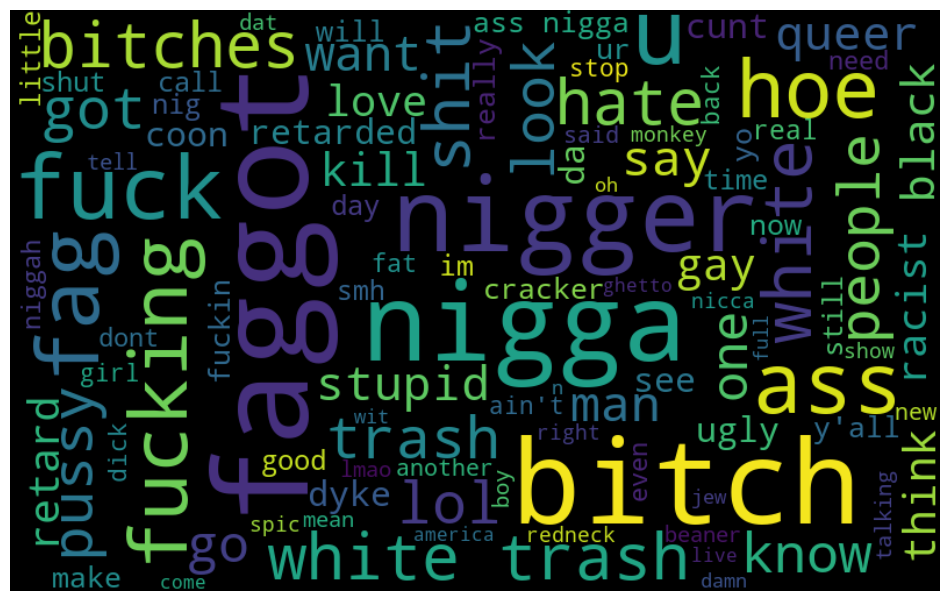

In [22]:
#taking all words classified as hate speech for visualization
hate_words = ' '.join([word for word in data['cleaned_tweet'][data['class'] == 0]])

wordcloud = WordCloud(width = 800, height = 500, max_font_size = 110,max_words = 100).generate(hate_words)
print('Hate words')

plt.figure(figsize= (12,8))
plt.imshow(wordcloud, interpolation = 'bilinear',cmap='YlOrBr')
plt.axis('off')

Offensive words


(np.float64(-0.5), np.float64(799.5), np.float64(499.5), np.float64(-0.5))

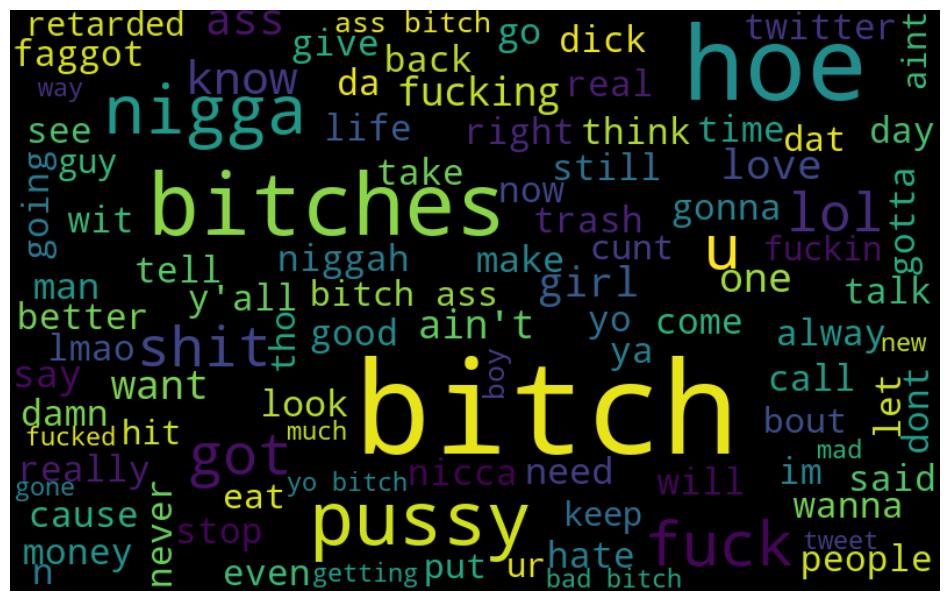

In [23]:
#taking all words classified as offensive speech for visualization
offen_words = ' '.join([word for word in data['cleaned_tweet'][data['class'] == 1]])

wordcloud = WordCloud(width = 800, height = 500, max_font_size = 110,max_words = 100).generate(offen_words)
print('Offensive words')

plt.figure(figsize= (12,8))
plt.imshow(wordcloud, interpolation = 'bilinear',cmap='YlOrBr')
plt.axis('off')

Normal words


(np.float64(-0.5), np.float64(799.5), np.float64(499.5), np.float64(-0.5))

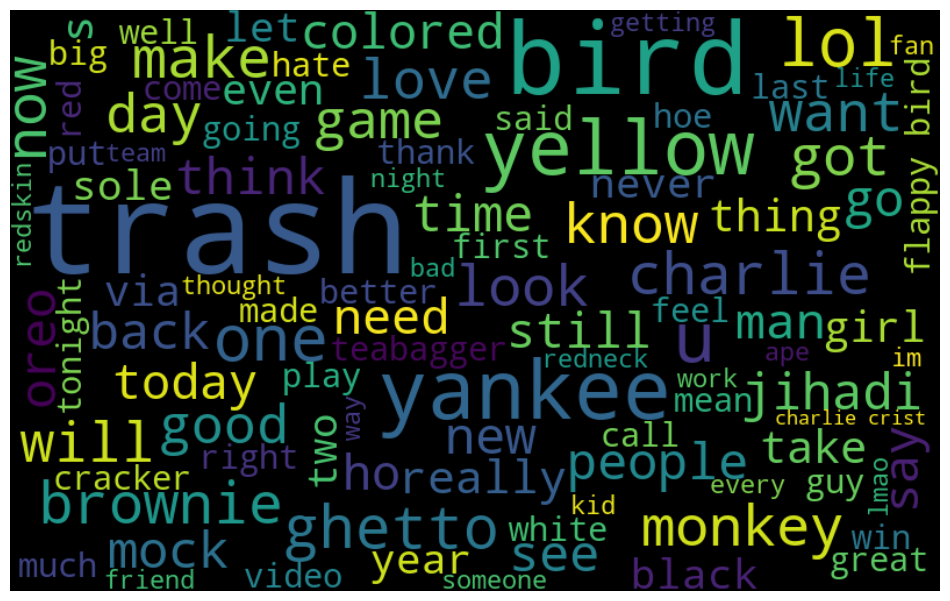

In [24]:
#taking all words classified as normal speech for visualization
normal_words = ' '.join([word for word in data['cleaned_tweet'][data['class'] == 2]])

wordcloud = WordCloud(width = 800, height = 500, max_font_size = 110,max_words = 100).generate(normal_words)
print('Normal words')

plt.figure(figsize= (12,8))
plt.imshow(wordcloud, interpolation = 'bilinear',cmap='YlOrBr')
plt.axis('off')

Stopword removal, lemmatization, tokenization can all be counterintuitive for the data we have on hand. Stopwords such as negation words carry important information in tweets, reducing words to their root form can miss significant variations in slang or tone, and standard tokenizers are built for formal text and can split or mangle slang and disguised spellings. The character-level features below handle these cases instead.

# Training and Test

Applying a stratified train-test split so that the class proportions are maintained in both sets, since we will have issues if less/more of the hate speech is present in either set.

In [26]:
from sklearn.model_selection import train_test_split

X = data["cleaned_tweet"]
y = data["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training examples: {len(X_train)}")
print(f"Test examples: {len(X_test)}")

print("\nTraining class proportions:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

Training examples: 19826
Test examples: 4957

Training class proportions:


class
0     5.77
1    77.43
2    16.80
Name: proportion, dtype: float64

# Model selection

TF-IDF is a good option, as it evaluates how important a word is to a document in relation to a larger collection of documents. This is exactly what we need in order to learn patterns in hate/offensive speech. 

To be more specific, word level and character level TF IDF are most helpful, since word level looks at the importance of the word, and character-level allows us to also consider slang ("y'all"), online abbreviations ("btw", "lol"), informal language ("dat", "ho", "im"), or slurs masked with special characters/numbers. 

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline

word_features = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2), #unigrams and bigrams
    max_features=50000, #controlling vocab size
    min_df=2 #ignores terms appearing in fewer than 2 documents as they are not important/noise
)

character_features = TfidfVectorizer(
    analyzer="char_wb", #identifies character sequences within word boundary
    ngram_range=(3, 5), #extracts character sequences of lengths 3, 4 and 5 which accounts for most common abbreviations
    max_features=50000,
    min_df=2
)

combined_features = FeatureUnion([ #combines the outputs of the two vectorizers horizontally into one feature matrix
    ("word_tfidf", word_features),
    ("character_tfidf", character_features)
])

# Training

After combining the two vectorizers, the features are 100,000. However, each individual tweet will have only very few of these features present. So, we are dealing with high dimensional but sparse data. Considering this, and the fact that we are essentially performing multiclass classification, we can go for classic Logistic regression as a baseline and see how it performs.

To deal with our class imbalance (offensive labelled tweets are overrepresented, hate speech labelled tweets are underrepresented), we apply class weighting. This ensures that errors in underrepresented classes are assigned a higher weight, and inversely, errors in overrepresented classes have lower weight. 

In [29]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("features", combined_features),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)



,steps,"[('features', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformer_list,"[('word_tfidf', ...), ('character_tfidf', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,input,'content'
,encoding,'utf-8'


# Evaluation

In [30]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)


y_pred = model.predict(X_test)
labels = ["hate speech", "offensive", "normal"]

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=[labels[i] for i in [0, 1, 2]],
        zero_division=0
    )
)

Accuracy: 0.8727
Macro F1-score: 0.7319

Classification report:
              precision    recall  f1-score   support

 hate speech       0.35      0.52      0.42       286
   offensive       0.96      0.89      0.92      3838
      normal       0.79      0.94      0.85       833

    accuracy                           0.87      4957
   macro avg       0.70      0.78      0.73      4957
weighted avg       0.89      0.87      0.88      4957



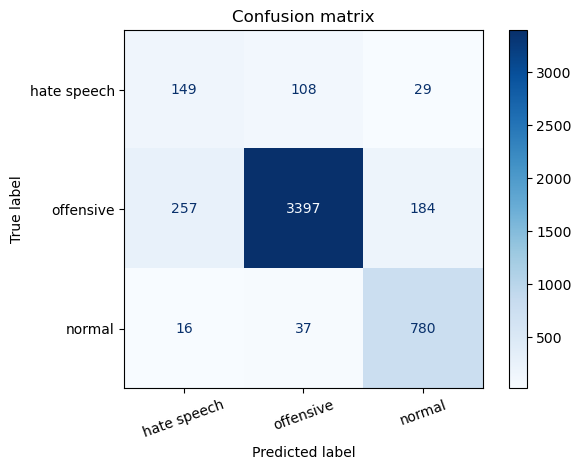

In [31]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    display_labels=[labels[i] for i in [0, 1, 2]],
    cmap="Blues",
    xticks_rotation=20
)

plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

### Helper functions

Two small helpers used for every model comparison below, so the table and plot code is written once.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

def summarize_models(predictions):
    """Overall scores plus hate speech (class 0) precision, recall and F1 for each model.
    `predictions` is a dict of {model name: predicted labels for X_test}."""
    rows = {}
    for name, preds in predictions.items():
        p, r, f, _ = precision_recall_fscore_support(y_test, preds, labels=[0], zero_division=0)
        rows[name] = {
            "accuracy": accuracy_score(y_test, preds),
            "macro F1": f1_score(y_test, preds, average="macro"),
            "weighted F1": f1_score(y_test, preds, average="weighted"),
            "hate precision": p[0],
            "hate recall": r[0],
            "hate F1": f[0],
        }
    return pd.DataFrame(rows).T.round(4)


def plot_confusion_matrices(predictions, normalize=None, title="Confusion matrices"):
    """Draw one confusion matrix per model, side by side."""
    fig, axes = plt.subplots(1, len(predictions), figsize=(6.5 * len(predictions), 5), squeeze=False)
    for ax, (name, preds) in zip(axes[0], predictions.items()):
        ConfusionMatrixDisplay.from_predictions(
            y_test, preds, labels=[0, 1, 2], display_labels=labels,
            normalize=normalize, values_format=".2f" if normalize else None,
            cmap="Blues", xticks_rotation=20, ax=ax, colorbar=False
        )
        ax.set_title(name)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Experiment: LinearSVC

Logistic regression gave a hate speech F1 of 0.42, with precision (0.35) well below recall (0.52). A linear SVM is a natural next step on this kind of high-dimensional, sparse TF-IDF data. It optimizes a hinge loss that focuses on the examples near the decision boundary, which is where hate speech and offensive tweets are hardest to separate.

The same TF-IDF features and `class_weight="balanced"` are used so that the only thing that changes is the classifier. The feature union is cloned so that the already-fitted logistic regression pipeline (`model`) is not affected.

In [32]:
from sklearn.svm import LinearSVC
from sklearn.base import clone

svc_model = Pipeline([
    ("features", clone(combined_features)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42
    ))
])

svc_model.fit(X_train, y_train)

,steps,"[('features', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformer_list,"[('word_tfidf', ...), ('character_tfidf', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,input,'content'
,encoding,'utf-8'


In [33]:
y_pred_svc = svc_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred_svc):.4f}")
print(f"Macro F1-score: {f1_score(y_test, y_pred_svc, average='macro'):.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_svc,
        labels=[0, 1, 2],
        target_names=[labels[i] for i in [0, 1, 2]],
        zero_division=0
    )
)

Accuracy: 0.8969
Macro F1-score: 0.7338

Classification report:
              precision    recall  f1-score   support

 hate speech       0.45      0.37      0.41       286
   offensive       0.94      0.94      0.94      3838
      normal       0.83      0.88      0.86       833

    accuracy                           0.90      4957
   macro avg       0.74      0.73      0.73      4957
weighted avg       0.89      0.90      0.89      4957



# Comparing Confusion Matrices

In [ ]:
plot_confusion_matrices(
    {"Logistic Regression": y_pred, "LinearSVC": y_pred_svc},
    normalize="true",
    title="Confusion matrices (normalized by true class)"
)

The true labels for hate speech went down. However, the true labels for offensive speech are better. Since our intent is specifically hate speech classification, Logistic Regression is actually the better choice.

### Tuning the regularization strength `C`

The default `C=1.0` is rarely the best value for TF-IDF features, and LinearSVC usually prefers stronger regularization (smaller `C`) when there are many features. `C` is tuned with stratified 5-fold cross-validation on the training set, optimizing macro F1 so that the minority hate speech class counts as much as the others. The test set stays untouched until the final comparison.

In [36]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

svc_pipeline = Pipeline([
    ("features", clone(combined_features)),
    ("classifier", LinearSVC(class_weight="balanced", random_state=42, max_iter=5000))
])

param_grid = {"classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0]}

grid = GridSearchCV(
    svc_pipeline,
    param_grid,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print(f"Best C: {grid.best_params_['classifier__C']}")
print(f"Best CV macro F1: {grid.best_score_:.4f}")

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best C: 0.1
Best CV macro F1: 0.7475


The best `C` found is 0.1, stronger regularization than the default of 1.0 (cross-validated macro F1 of about 0.7475). The test-set numbers for the tuned model are shown below.

In [ ]:
best_svc = grid.best_estimator_
y_pred_best = best_svc.predict(X_test)

print("Tuned LinearSVC classification report:")
print(
    classification_report(
        y_test,
        y_pred_best,
        labels=[0, 1, 2],
        target_names=[labels[i] for i in [0, 1, 2]],
        zero_division=0
    )
)

# Summary table: overall metrics plus hate speech (class 0) precision/recall/F1
summarize_models({
    "Logistic Regression": y_pred,
    "LinearSVC (default C)": y_pred_svc,
    f"LinearSVC (C={grid.best_params_['classifier__C']})": y_pred_best,
})

# Attempting to improve Logistic Regression

In [39]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

lr_pipeline = Pipeline([
    ("features", clone(combined_features)),
    ("classifier", LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000))
])

lr_grid = GridSearchCV(
    lr_pipeline,
    {"classifier__C": [0.3, 1, 3, 10, 30]},
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)
lr_grid.fit(X_train, y_train)

best_C = lr_grid.best_params_["classifier__C"]
print(f"Best C: {best_C}  (CV macro F1: {lr_grid.best_score_:.4f})")

pd.DataFrame(lr_grid.cv_results_)[["param_classifier__C", "mean_test_score", "std_test_score"]]

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best C: 1  (CV macro F1: 0.7374)


,param_classifier__C,mean_test_score,std_test_score
0,0.3,0.724703,0.008658
1,1.0,0.737358,0.009556
2,3.0,0.736736,0.008192
3,10.0,0.731208,0.008377
4,30.0,0.724088,0.011606


In [40]:
# LR with the tuned C (no other changes)
lr_tuned = lr_grid.best_estimator_        # already refit on the full training set
y_pred_lr_tuned = lr_tuned.predict(X_test)

if best_C == 1:
    print("Note: cross-validation kept the default C=1, so this model is identical to the baseline.\n")

print(classification_report(
    y_test, y_pred_lr_tuned, labels=[0, 1, 2],
    target_names=[labels[i] for i in [0, 1, 2]], zero_division=0
))

Note: cross-validation kept the default C=1, so this model is identical to the baseline.

              precision    recall  f1-score   support

 hate speech       0.35      0.52      0.42       286
   offensive       0.96      0.89      0.92      3838
      normal       0.79      0.94      0.85       833

    accuracy                           0.87      4957
   macro avg       0.70      0.78      0.73      4957
weighted avg       0.89      0.87      0.88      4957



### How reliable are the hate speech labels?

Each tweet was labelled by at least 3 people. The vote columns were dropped earlier, so the CSV is reloaded into a separate dataframe (`raw`) to measure how much the annotators agreed. A tweet is *unanimous* when everyone chose the same label.

In [ ]:
raw = pd.read_csv('labeled_data.csv')
assert (raw['class'].values == data['class'].values).all()   # same rows, same order as `data`

votes = raw[['hate_speech', 'offensive_language', 'neither']]
raw['agreement'] = votes.max(axis=1) / raw['count']           # share of annotators who chose the winning label

agreement_summary = (
    raw.assign(unanimous=raw['agreement'] == 1)
       .groupby('class')['unanimous']
       .agg(tweets='size', unanimous='mean')
)
agreement_summary.index = [labels[i] for i in agreement_summary.index]
agreement_summary['unanimous'] = (agreement_summary['unanimous'] * 100).round(1)
agreement_summary['not unanimous'] = (100 - agreement_summary['unanimous']).round(1)
display(agreement_summary)

hate_share = agreement_summary.loc['hate speech', 'not unanimous']
print(f"\n{hate_share:.0f}% of hate-labelled tweets were NOT unanimous.")

hate = raw[raw['class'] == 0]
split_2_of_3 = ((hate['hate_speech'] == 2) & (hate['count'] == 3)).sum()
print(f"{split_2_of_3} of {len(hate)} hate-labelled tweets ({split_2_of_3 / len(hate) * 100:.0f}%) won by a bare 2-vs-1 vote.")

ax = agreement_summary[['unanimous', 'not unanimous']].plot(kind='bar', stacked=True, figsize=(7, 4), rot=0)
ax.set_ylabel('% of tweets')
ax.set_title('Annotator agreement by class')
plt.tight_layout()
plt.show()

Hate speech is by far the least reliably labelled class: most of its tweets were decided by a split vote. This limits how well *any* model can score on it, and motivates the agreement weights below.

In [ ]:
# Agreement for the training rows only (`raw` is built in the agreement cell above and shares the index of `data`)
train_weights = (raw.loc[X_train.index, 'agreement'] ** 2).values

lr_weighted = Pipeline([
    ("features", clone(combined_features)),
    ("classifier", LogisticRegression(C=best_C, class_weight="balanced", random_state=42, max_iter=1000))
])
lr_weighted.fit(X_train, y_train, classifier__sample_weight=train_weights)

y_pred_lr_weighted = lr_weighted.predict(X_test)

print(classification_report(
    y_test, y_pred_lr_weighted, labels=[0, 1, 2],
    target_names=[labels[i] for i in [0, 1, 2]], zero_division=0
))

In [ ]:
summarize_models({
    "LR baseline (C=1)": y_pred,
    f"LR (C={best_C}) + agreement weights": y_pred_lr_weighted,
})

In [ ]:
plot_confusion_matrices(
    {
        f"LR (C={best_C})": y_pred,
        f"LR (C={best_C}) + agreement weights": y_pred_lr_weighted,
    },
    title="Confusion matrices (raw counts)"
)

The agreement weights also do not make a difference, the model does not improve substantially. 